# Actividad 5 · AI-SupportAssist · Programa integrado
**Estudiante:** Efraín Cuatecontzi Mendoza. **Proyecto:** NovaMarket, componente de triaje.

**Ejecutar en Colab:** usa CPU y ejecuta todas las celdas en orden. Instala dependencias antes de importarlas. Si Colab solicita reiniciar, reinicia y vuelve a ejecutar desde el inicio. Con `GUARDAR_EN_DRIVE=True` se conservan datos, SQLite, artefactos y evidencias en Drive; con False descarga el ZIP final antes de cerrar la sesión. No requiere tokens ni GPU.

**Alcance:** clasificación de 27 intenciones con datos públicos híbridos sintéticos en inglés; no valida producción en español, auto-resolución, RAG, CSAT ni ROI. El 92 % de enrutamiento de fase 1 sigue siendo una meta de negocio.

**Se completa:** ROC-AUC por clase y macro; curvas ROC; folds persistidos y huellas; prueba de configuración real de MLflow; lotes separados por ejecución; verificación de parámetros, métricas, archivos y recarga de ambos Pipelines desde MLflow; exportación de scripts, README, CHANGELOG y paquete ZIP. Las salidas se generan al ejecutar, no se reutilizan las de los cuadernos originales.

## 1 Entorno reproducible
Se fija la versión de MLflow. Al finalizar se exportan las versiones efectivas de todas las dependencias. La semilla controla las particiones y los estimadores; los tiempos pueden variar entre máquinas.


In [2]:
import sys
import subprocess
import importlib.util
import os

IN_COLAB = (
    importlib.util.find_spec("google.colab") is not None
    if importlib.util.find_spec("google")
    else False
)

print("Versión de Python:", sys.version.split()[0], flush=True)

if IN_COLAB:
    # Conjunto utilizado en la prueba local del programa.
    paquetes = [
        "mlflow==3.5.0",
        "scikit-learn==1.7.2",
        "pandas==2.3.3",
        "numpy==2.2.6",
        "scipy==1.16.3",
        "matplotlib==3.10.7",
        "joblib==1.5.2",
        "SQLAlchemy==2.0.43",
        "packaging==25.0",
    ]

    print("Instalando dependencias; el progreso aparecerá abajo...",
          flush=True)

    subprocess.run(
        [
            sys.executable, "-m", "pip", "install",
            "--disable-pip-version-check",
            "--only-binary=numpy,scipy,scikit-learn,pandas,matplotlib",
            "--timeout=60",
            "--retries=2",
            *paquetes,
        ],
        check=True,
        timeout=600,
    )

os.environ["MLFLOW_ENABLE_SYSTEM_METRICS_LOGGING"] = "false"

print("\nINSTALACIÓN FINALIZADA.", flush=True)
print("Si se cambiaron paquetes, reinicia la sesión manualmente una vez.")

Versión de Python: 3.13.16
Instalando dependencias; el progreso aparecerá abajo...

INSTALACIÓN FINALIZADA.
Si se cambiaron paquetes, reinicia la sesión manualmente una vez.


In [3]:
from pathlib import Path
import re, json, hashlib, unicodedata, urllib.request, platform, time, shutil, uuid, importlib.util
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, scipy, mlflow, mlflow.sklearn, sqlalchemy, packaging
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay, roc_auc_score, roc_curve
from scipy.stats import binomtest
from mlflow.tracking import MlflowClient
from IPython.display import display

GUARDAR_EN_DRIVE = True
if IN_COLAB and GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Act5_GP/Actividad5')
else:
    ROOT = Path(os.environ.get('ACT5_ROOT', str(Path.cwd() / 'Actividad5')))
ROOT = ROOT.resolve()
BATCH_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '_' + uuid.uuid4().hex[:8]
RAW, PROCESSED, SOURCES = [ROOT / p for p in ['datos/datos_ini', 'datos/datos_limp', 'fuentes']]
REPORTS = ROOT/'evidencias'/BATCH_ID
MODELS = ROOT/'modelos'/BATCH_ID
TRACKING = ROOT/'.mlflow_local'
for p in [RAW, PROCESSED, SOURCES, REPORTS, MODELS, TRACKING]: p.mkdir(parents=True, exist_ok=True)
SEED = 42
np.random.seed(SEED)
def sha256(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_json(obj, path): Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')
versions = {name: module.__version__ for name,module in [('numpy',np),('pandas',pd),('scikit-learn',sklearn),('scipy',scipy),('matplotlib',__import__('matplotlib')),('mlflow',mlflow),('joblib',joblib),('sqlalchemy',sqlalchemy),('packaging',packaging)]}
(ROOT/'requirements_effective.txt').write_text(''.join(f'{k}=={v}\n' for k,v in versions.items()))
save_json({'python':platform.python_version(),'platform':platform.platform(),'packages':versions}, REPORTS/'environment.json')
print('Directorio del proyecto:', ROOT)
display(pd.DataFrame(versions.items(), columns=['Paquete','Versión']))

# Guardar cada lote por separado impide mezclar evidencias de varias ejecuciones.
tracking_uri = 'sqlite:///' + str((TRACKING/'mlflow.db').resolve())
mlflow.set_tracking_uri(tracking_uri)
client = MlflowClient(tracking_uri=tracking_uri)
def set_experiment_local(name):
    exp = client.get_experiment_by_name(name)
    if exp is None:
        client.create_experiment(name, artifact_location=(TRACKING/'artefactos').as_uri())
    else:
        assert exp.lifecycle_stage == 'active', 'El experimento está eliminado. Restaura o elige otro nombre.'
        assert exp.artifact_location == (TRACKING/'artefactos').as_uri(), 'El almacén cambió de ruta: usa una raíz nueva o conserva la ubicación original.'
    mlflow.set_experiment(name)
    return client.get_experiment_by_name(name).experiment_id


Mounted at /content/drive
Directorio del proyecto: /content/drive/MyDrive/Act5_GP/Actividad5


,Paquete,Versión
0,numpy,2.2.6
1,pandas,2.3.3
2,scikit-learn,1.7.2
3,scipy,1.16.3
4,matplotlib,3.10.7
5,mlflow,3.5.0
6,joblib,1.5.2
7,sqlalchemy,2.0.43
8,packaging,25.0


2026/10/19 04:24:58 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 04:24:59 INFO mlflow.store.db.utils: Updating database tables
2026-10-19 04:24:59 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
2026-10-19 04:24:59 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
2026-10-19 04:24:59 INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
2026-10-19 04:24:59 INFO  [alembic.runtime.migration] Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
2026-10-19 04:24:59 INFO  [alembic.runtime.migration] Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
2026-10-19 04:24:59 INFO  [alembic.runtime.migration] Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
2026-10-19 04:24:59 INFO  [alembic.runtime.migration] Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
2026-10-19 04:24:59 INFO  [alembic.runtime.mig

## 2 Origen y estructura del dataset
**Autor:** Bitext Innovations (2024). **Repositorio:** [Bitext Customer Support](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset). **Licencia declarada:** CDLA Sharing 1.0, [texto de licencia](https://cdla.dev/sharing-1-0/).

La ficha describe generación híbrida sintética con supervisión lingüística. No son tickets reales de NovaMarket. Se conserva la ficha original, la revisión fija del repositorio y el SHA-256 del CSV. La cantidad de clases se calcula desde los datos porque la descripción de categorías de la ficha no coincide plenamente con el archivo.

| Campo | Significado | Uso |
|---|---|---|
| flags | Etiquetas de variación lingüística | Análisis exploratorio, nunca predictor |
| instruction | Solicitud del usuario | Única entrada del modelo |
| category | Grupo semántico | Contexto y mapeo de salida |
| intent | Intención etiquetada | Variable objetivo |
| response | Respuesta de ejemplo | Excluida para evitar fuga de información |

No se inventan etiquetas Técnico/Facturación/Dudas Generales: se conservan las intenciones y categorías verificadas del dataset. Su correspondencia con departamentos de NovaMarket requerirá validación posterior.


In [4]:
REPO = 'bitext/Bitext-customer-support-llm-chatbot-training-dataset'
REVISION = '430d1a89bd93bd1fa23c16f29dd53e73f0087443'
CSV_NAME = 'Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv'
EXPECTED_SHA = '6f81102b0100b97b8468eb04368033a23206bf1fde9d53500d5806ec1001a434'
BASE_URL = f'https://huggingface.co/datasets/{REPO}/resolve/{REVISION}/'
def download_verified(url, dest, expected=None):
    dest=Path(dest)
    if dest.exists():
        if expected and sha256(dest)!=expected:
            raise ValueError(f'Archivo alterado: {dest}. Conserva una copia y revisa su procedencia.')
        return
    temp=dest.with_suffix(dest.suffix+'.part')
    try:
        with urllib.request.urlopen(url,timeout=120) as response, temp.open('wb') as f:
            shutil.copyfileobj(response,f)
        if expected and sha256(temp)!=expected: raise ValueError('SHA-256 inesperado en descarga')
        temp.replace(dest)
    finally:
        temp.unlink(missing_ok=True)
download_verified(BASE_URL+CSV_NAME, RAW/CSV_NAME, EXPECTED_SHA)
download_verified(BASE_URL+'README.md', RAW/'README_fuente.md')
# La licencia se documenta por URL y declaración de la revisión fijada.
df_original = pd.read_csv(RAW/CSV_NAME, dtype=str)
assert set(df_original.columns)=={'instruction','intent','category','flags','response'}
assert len(df_original)==26872
print('Filas y columnas:',df_original.shape)
print('Intenciones:',df_original.intent.nunique(),'Categorías:',df_original.category.nunique())
display(df_original[['instruction','intent','category']].head())
display(df_original.isna().sum().to_frame('Faltantes'))
save_json({'dataset':REPO,'revision':REVISION,'url':BASE_URL+CSV_NAME,'sha256':EXPECTED_SHA,
           'source_card_sha256':sha256(RAW/'README_fuente.md'),'license':'CDLA Sharing 1.0',
           'license_url':'https://cdla.dev/sharing-1-0/'}, ROOT/'datos/dataset.lock.json')


Filas y columnas: (26872, 5)
Intenciones: 27 Categorías: 11


,instruction,intent,category
0,question about cancelling order {{Order Number}},cancel_order,ORDER
1,i have a question about cancelling oorder {{Or...,cancel_order,ORDER
2,i need help cancelling puchase {{Order Number}},cancel_order,ORDER
3,I need to cancel purchase {{Order Number}},cancel_order,ORDER
4,"I cannot afford this order, cancel purchase {{...",cancel_order,ORDER


,Faltantes
flags,0
instruction,0
category,0
intent,0
response,0


## 3 Preparación y auditoría
Se normaliza Unicode y espacio en blanco, se mantienen negaciones, acentos, signos y errores ortográficos útiles. Las entidades entre llaves se sustituyen por un marcador común para evitar aprender pistas de la etiqueta desde el tipo de entidad. Las expresiones regulares de correo y teléfono son controles básicos, no una garantía completa de anonimización.

Se conserva la posición original y una clave de texto para auditar exclusiones. Se apartan solicitudes vacías, etiquetas vacías, textos con etiquetas contradictorias y duplicados exactos tras normalización. Se conserva la primera aparición por una regla determinista; no se utilizan respuestas ni atributos futuros para decidir. Un cliente puede abrir varios tickets: nunca se deduplica por persona o correo.


In [5]:
CLEANING_SOURCE = "import pandas as pd\nimport re, unicodedata\n\ndef clean_text(value):\n    if pd.isna(value): return ''\n    text = unicodedata.normalize('NFKC', str(value)).strip().lower()\n    text = re.sub(r'\\{\\{.*?\\}\\}', ' entity ', text)\n    text = re.sub(r'[\\w.+-]+@[\\w.-]+\\.[a-z]{2,}', ' email ', text)\n    text = re.sub(r'(?<!\\w)\\+?\\d[\\d ()-]{7,}\\d(?!\\w)', ' phone ', text)\n    return re.sub(r'\\s+', ' ', text).strip()\n\n"
(SOURCES/'datos_prep.py').write_text(CLEANING_SOURCE,encoding='utf-8')
spec = importlib.util.spec_from_file_location("act5_datos_prep", SOURCES/"datos_prep.py")
prep_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(prep_module)
clean_text = prep_module.clean_text

audit = df_original.copy()
audit.insert(0, 'source_row', np.arange(len(audit)))
audit['text_clean'] = audit.instruction.map(clean_text)
audit['intent_clean'] = audit.intent.fillna('').str.strip().str.lower()
audit['text_sha256'] = audit.text_clean.map(lambda s: hashlib.sha256(s.encode()).hexdigest())
audit['exclusion_reason'] = ''
invalid = audit.text_clean.eq('') | audit.intent_clean.eq('') | audit.category.fillna('').str.strip().eq('')
audit.loc[invalid,'exclusion_reason'] = 'texto_o_etiqueta_vacios'
valid = audit.loc[~invalid]
conflicts = valid.groupby('text_sha256').intent_clean.nunique()
conflict_keys = set(conflicts[conflicts>1].index)
audit.loc[~invalid & audit.text_sha256.isin(conflict_keys),'exclusion_reason'] = 'etiquetas_contradictorias'
eligible = audit.exclusion_reason.eq('')
duplicates = audit.loc[eligible].duplicated('text_sha256', keep='first')
audit.loc[duplicates[duplicates].index,'exclusion_reason'] = 'texto_duplicado'
clean = audit.loc[audit.exclusion_reason.eq(''), ['source_row','text_clean','text_sha256','intent_clean','category','flags']].copy()
assert not clean.text_sha256.duplicated().any()
assert clean.groupby('intent_clean').category.nunique().max()==1
assert clean.intent_clean.value_counts().min()>=10
clean.to_csv(PROCESSED/'tickets_clean_v1.csv', index=False)
# Auditoría completa: incluye registros conservados y descartados.
audit[['source_row','text_sha256','intent_clean','exclusion_reason']].to_csv(REPORTS/'audit_all_rows.csv',index=False)
quality = {'raw_rows':len(audit),'clean_rows':len(clean),'excluded_rows':len(audit)-len(clean),
           'exclusion_reasons':audit.exclusion_reason.replace('','conservado').value_counts().to_dict(),
           'intents':int(clean.intent_clean.nunique()),'categories':int(clean.category.nunique()),
           'missing_raw':df_original.isna().sum().astype(int).to_dict(),
           'empty_raw':{c:int(df_original[c].fillna('').str.strip().eq('').sum()) for c in df_original},
           'conflicting_texts':len(conflict_keys)}
audit[['source_row','text_sha256','intent_clean','exclusion_reason']].to_csv(PROCESSED/'auditoria_v1.csv',index=False)
save_json(quality,REPORTS/'quality.json')
display(pd.DataFrame(quality['exclusion_reasons'].items(),columns=['Estado','Filas']))
print('Filas limpias:',len(clean))


,Estado,Filas
0,conservado,24014
1,texto_duplicado,2858


Filas limpias: 24014


## 4 Visualización e interpretación de calidad
Los gráficos permiten revisar desbalance, longitudes y exclusiones. Se examinan las solicitudes de longitud extrema sin eliminarlas automáticamente. No se fabrican inconsistencias para aparentar limpieza: si una regla no encuentra problemas, se informa cero.


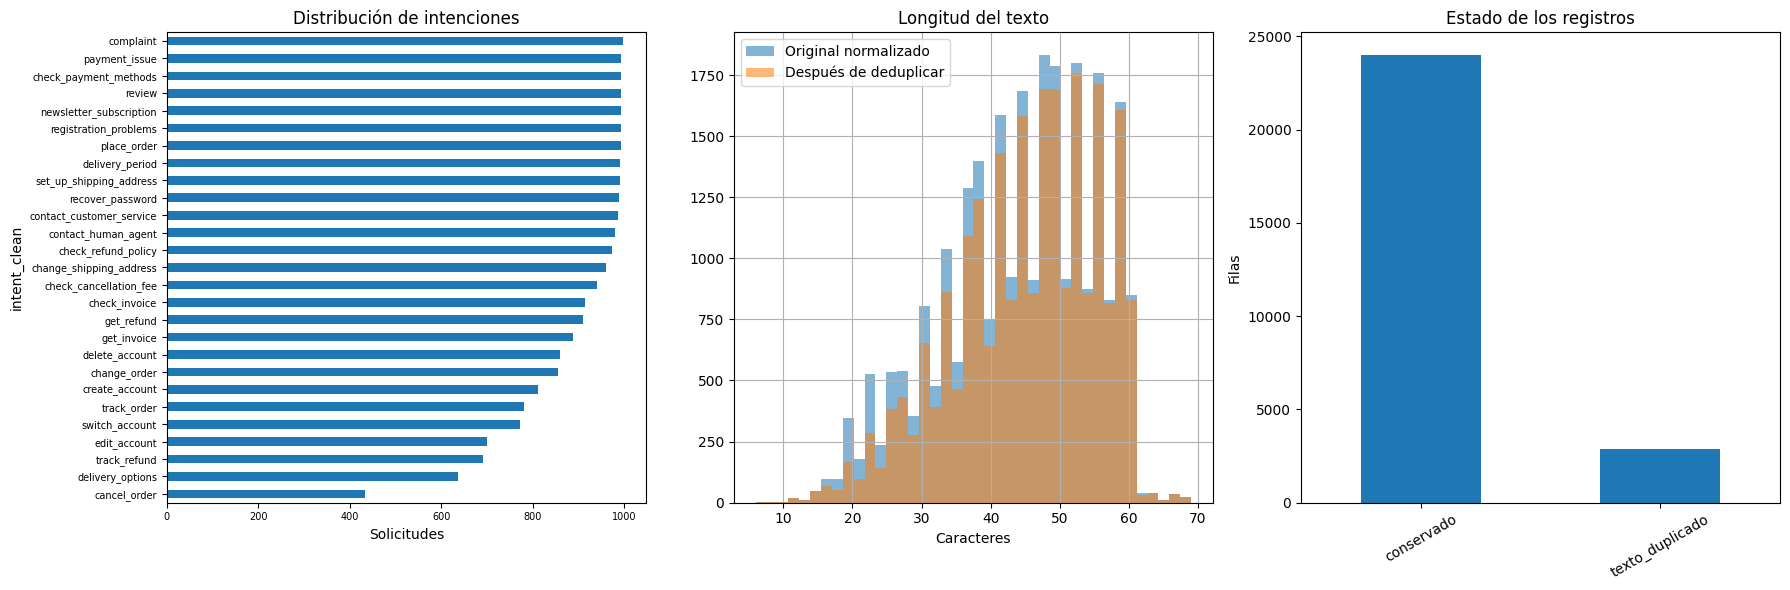

Desbalance máximo/mínimo después de limpiar: 2.30.
Las exclusiones reducen redundancia exacta; no demuestran diversidad de plantillas ni cobertura real del negocio.


,text_clean,intent_clean,characters
16147,"i have paid entity entity for an order, how oc...",get_refund,69
16327,"i paid entity entity for a product, i want to ...",get_refund,69
16349,"i paid entity entity for a product, where can ...",get_refund,69
16672,"i paid entity entity for this product, assista...",get_refund,69
25951,i expect a restitution of entity entity has it...,track_refund,69


In [6]:
fig, axes = plt.subplots(1,3,figsize=(18,6))
clean.intent_clean.value_counts().sort_values().plot.barh(ax=axes[0],fontsize=7)
axes[0].set_title('Distribución de intenciones'); axes[0].set_xlabel('Solicitudes')
audit.text_clean.str.len().hist(bins=40,ax=axes[1],alpha=.55,label='Original normalizado')
clean.text_clean.str.len().hist(bins=40,ax=axes[1],alpha=.55,label='Después de deduplicar')
axes[1].set_title('Longitud del texto'); axes[1].set_xlabel('Caracteres'); axes[1].legend()
pd.Series(quality['exclusion_reasons']).plot.bar(ax=axes[2],rot=30)
axes[2].set_title('Estado de los registros'); axes[2].set_ylabel('Filas')
fig.tight_layout(); fig.savefig(REPORTS/'quality.png',dpi=160,bbox_inches='tight'); plt.show()
counts = clean.intent_clean.value_counts()
print(f'Desbalance máximo/mínimo después de limpiar: {counts.max()/counts.min():.2f}.')
print('Las exclusiones reducen redundancia exacta; no demuestran diversidad de plantillas ni cobertura real del negocio.')
display(clean.assign(characters=clean.text_clean.str.len()).nlargest(5,'characters')[['text_clean','intent_clean','characters']])


## 5 Partición y versionamiento
Prueba estratificada del 20 % y cinco folds estratificados sobre el 80 % restante. Se guarda qué fila pertenece a cada partición y fold; ambos algoritmos usan exactamente los mismos folds. TF-IDF aprende vocabulario e IDF dentro del Pipeline de cada fold.

`datos/dataset.lock.json` fija el origen; `datos/preparacion_v1.json` fija SHA-256 de los datos limpios, split, folds y módulo de limpieza. Cada lote conserva una copia. No se inventa un commit Git ni se configura una identidad ficticia: si no existe un repositorio inicializado se informa `sin_commit`. Al final se incluyen instrucciones para tu repositorio existente `efrainkun-ai/Act5_GP`.


In [7]:
train, test = train_test_split(clean,test_size=.2,random_state=SEED,stratify=clean.intent_clean)
assert set(train.text_sha256).isdisjoint(set(test.text_sha256))
split = pd.concat([train.assign(split='train'),test.assign(split='test')])[['source_row','text_sha256','split']]
split.to_csv(PROCESSED/'split_v1.csv',index=False)
X_train, y_train = train.text_clean, train.intent_clean
X_test, y_test = test.text_clean, test.intent_clean
folds=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(X_train,y_train))
fold_rows=[]
for fold,(fit_idx,val_idx) in enumerate(folds):
    assert set(train.iloc[fit_idx].text_sha256).isdisjoint(set(train.iloc[val_idx].text_sha256))
    fold_rows.append(pd.DataFrame({'source_row':train.iloc[val_idx].source_row.to_numpy(),
        'text_sha256':train.iloc[val_idx].text_sha256.to_numpy(),'validation_fold':fold}))
fold_manifest=pd.concat(fold_rows,ignore_index=True)
assert len(fold_manifest)==len(train) and not fold_manifest.source_row.duplicated().any()
fold_manifest.to_csv(PROCESSED/'folds_v1.csv',index=False)
manifest={'dataset':REPO,'revision':REVISION,'license':'cdla-sharing-1.0','raw_sha256':EXPECTED_SHA,
 'processed_sha256':sha256(PROCESSED/'tickets_clean_v1.csv'),'split_sha256':sha256(PROCESSED/'split_v1.csv'),
 'folds_sha256':sha256(PROCESSED/'folds_v1.csv'),'cleaning_code_sha256':sha256(SOURCES/'datos_prep.py'),
 'seed':SEED,'test_size':.2,'cleaning_version':'v1','target':'intent_clean','predictor':'text_clean',
 'train_rows':len(train),'test_rows':len(test),'folds':5}
save_json(manifest,ROOT/'datos/preparacion_v1.json')
save_json(manifest,REPORTS/'dataset_manifest_v1.json')
git_commit='sin_commit'
if shutil.which('git'):
    proc=subprocess.run(['git','-C',str(ROOT),'rev-parse','HEAD'],capture_output=True,text=True)
    if proc.returncode==0: git_commit=proc.stdout.strip()
# Los hashes versionan también ejecuciones sin un repositorio Git inicializado.
save_json({'git_commit_observado':git_commit,'batch_id':BATCH_ID,'manifest':manifest},REPORTS/'provenance.json')
print('Train:',len(train),'Test:',len(test),'Folds:',len(folds),'Commit observado:',git_commit)
print('No hay textos normalizados idénticos entre entrenamiento y prueba.')


Train: 19211 Test: 4803 Folds: 5 Commit observado: sin_commit
No hay textos normalizados idénticos entre entrenamiento y prueba.


## 6 Diseño experimental y MLflow
**Referencia trivial:** clase más frecuente. **Modelos:** MultinomialNB, rápido para texto disperso, y LinearSVC, que permite fronteras lineales regularizadas. En ambos se comparan unigramas y bigramas. NB prueba alpha 0.1, 0.5 y 1.0 (suavizado); SVM prueba C 0.5, 1 y 2 (regularización). Son seis configuraciones y cinco folds por modelo: 60 ajustes de búsqueda, más los reajustes finales.

Se prioriza F1 macro para dar el mismo peso a cada intención y se reportan accuracy, precisión y recall macro. Los mismos folds se utilizan para ambos modelos. Cada candidato se registra como una ejecución hija, incluyendo resultados por fold; cada ejecución padre guarda el Pipeline completo, configuración, métricas, firma, datos de ejemplo y artefactos. El baseline es descriptivo y no participa en la selección.


### 6.1 Prueba de configuración de MLflow
Este run registra valores de control, no resultados predictivos. Comprueba estado, parámetros, métricas y descarga exacta de un archivo antes de entrenar.


In [8]:
set_experiment_local('Act5_GP_Configuracion_Integrado')
control_file=REPORTS/'mlflow_control.txt'
control_file.write_text('Actividad 5: verificación de persistencia de MLflow.\n',encoding='utf-8')
with mlflow.start_run(run_name='verificacion_'+BATCH_ID) as control_run:
    mlflow.set_tags({'batch_id':BATCH_ID,'kind':'configuration'})
    mlflow.log_param('proyecto','AI-SupportAssist')
    mlflow.log_metric('valor_control',1.0)
    mlflow.log_artifact(str(control_file))
    mlflow.log_artifact(str(REPORTS/'environment.json'))
control=client.get_run(control_run.info.run_id)
download_dir=REPORTS/'descargas_verificadas'
download_dir.mkdir(exist_ok=True)
control_download=client.download_artifacts(control.info.run_id,'mlflow_control.txt',str(download_dir))
controls={'finished':control.info.status=='FINISHED','parametro':control.data.params.get('proyecto')=='AI-SupportAssist',
          'metrica':control.data.metrics.get('valor_control')==1.0,'artefacto':sha256(control_download)==sha256(control_file)}
assert all(controls.values()),controls
save_json({'run_id':control.info.run_id,'controles':controls},REPORTS/'mlflow_configuracion.json')
print('MLflow configurado y persistencia validada:',controls)


MLflow configurado y persistencia validada: {'finished': True, 'parametro': True, 'metrica': True, 'artefacto': True}


In [9]:
scoring={'f1_macro':'f1_macro','accuracy':'accuracy'}
specs = {
 'MultinomialNB':(MultinomialNB(),{'tfidf__ngram_range':[(1,1),(1,2)],'clf__alpha':[.1,.5,1.]}),
 'LinearSVC':(LinearSVC(random_state=SEED,max_iter=10000),{'tfidf__ngram_range':[(1,1),(1,2)],'clf__C':[.5,1.,2.]})}
experiment_name='Actividad5_AI_SupportAssist_Intent_v2'
EXPERIMENT_ID=set_experiment_local(experiment_name)
model_uris={}
scores_by_model={}
def metrics(y,p):
    return {'accuracy':accuracy_score(y,p),'precision_macro':precision_score(y,p,average='macro',zero_division=0),
            'recall_macro':recall_score(y,p,average='macro',zero_division=0),'f1_macro':f1_score(y,p,average='macro',zero_division=0)}
dummy=DummyClassifier(strategy='most_frequent').fit(np.zeros((len(y_train),1)),y_train)
baseline=metrics(y_test,dummy.predict(np.zeros((len(y_test),1))))
save_json(baseline,REPORTS/'baseline.json')
searches, predictions, records = {}, {}, []
for name,(clf,grid_params) in specs.items():
    print('Entrenando:',name,flush=True)
    pipe=Pipeline([('tfidf',TfidfVectorizer(min_df=2,max_features=20000,sublinear_tf=True)),('clf',clf)])
    with mlflow.start_run(run_name=name) as run:
        mlflow.set_tags({'batch_id':BATCH_ID,'kind':'model'})
        mlflow.set_tags({'dataset_revision':REVISION,'git_commit':git_commit,'cleaning_version':'v1','scope':'synthetic_english_prototype'})
        mlflow.log_params({'seed':SEED,'folds':5,'selection_metric':'f1_macro','dataset_sha256':manifest['processed_sha256'],
                           'split_sha256':manifest['split_sha256'],'folds_sha256':manifest['folds_sha256'],'train_rows':len(train),'test_rows':len(test),'max_features':20000,'min_df':2})
        start=time.perf_counter()
        grid=GridSearchCV(pipe,grid_params,cv=folds,scoring=scoring,refit='f1_macro',n_jobs=1,return_train_score=True,error_score='raise')
        grid.fit(X_train,y_train)
        fit_seconds=time.perf_counter()-start
        cv_results=pd.DataFrame(grid.cv_results_)
        cv_results.to_csv(REPORTS/f'{name}_grid.csv',index=False)
        for idx,row in cv_results.iterrows():
            with mlflow.start_run(run_name=f'{name}_candidate_{idx}',nested=True):
                mlflow.set_tags({'batch_id':BATCH_ID,'kind':'candidate'})
                mlflow.log_params({k:str(v) for k,v in row['params'].items()})
                mlflow.log_metrics({'cv_f1_macro_mean':row['mean_test_f1_macro'],'cv_f1_macro_std':row['std_test_f1_macro'],
                                    'cv_accuracy_mean':row['mean_test_accuracy'],'mean_fit_seconds':row['mean_fit_time']})
                for fold in range(5): mlflow.log_metric(f'fold_{fold}_f1_macro',row[f'split{fold}_test_f1_macro'])
        best=grid.best_estimator_
        pred=best.predict(X_test)
        predictions[name]=pred
        classes=best.named_steps['clf'].classes_
        assert set(classes)==set(y_test.unique())
        scores=best.predict_proba(X_test) if hasattr(best,'predict_proba') else best.decision_function(X_test)
        assert scores.shape==(len(y_test),len(classes))
        aucs=[roc_auc_score((y_test.to_numpy()==label).astype(int),scores[:,j]) for j,label in enumerate(classes)]
        scores_by_model[name]=(classes,scores)
        pd.DataFrame({'intent':classes,'roc_auc_ovr':aucs}).to_csv(REPORTS/f'{name}_auc_por_clase.csv',index=False)
        train_metrics=metrics(y_train,best.predict(X_train)); test_metrics=metrics(y_test,pred)
        test_metrics['roc_auc_macro_ovr']=float(np.mean(aucs))
        # Latencia por solicitud tras calentamiento; depende del hardware y no incluye red ni CRM.
        samples=X_test.iloc[:min(200,len(X_test))].tolist(); best.predict(samples[:5])
        lat=[]
        for text in samples:
            start=time.perf_counter(); best.predict([text]);lat.append((time.perf_counter()-start)*1000)
        row={'model':name,'cv_f1_mean':grid.best_score_,'cv_f1_std':float(cv_results.iloc[grid.best_index_]['std_test_f1_macro']),
             **{'test_'+k:v for k,v in test_metrics.items()},'train_f1_macro':train_metrics['f1_macro'],
             'search_seconds':fit_seconds,'latency_p50_ms':float(np.median(lat)),'latency_p95_ms':float(np.percentile(lat,95)),
             'run_id':run.info.run_id,'best_params':str(grid.best_params_)}
        mlflow.log_params({'best_'+k:str(v) for k,v in grid.best_params_.items()})
        mlflow.log_metrics({k:v for k,v in row.items() if isinstance(v,(int,float))})
        mlflow.log_dict(manifest,'dataset_manifest.json')
        mlflow.log_artifact(str(REPORTS/f'{name}_grid.csv'))
        mlflow.log_artifact(str(REPORTS/'quality.json'))
        mlflow.log_artifact(str(REPORTS/'quality.png'))
        signature=mlflow.models.infer_signature(X_train.iloc[:3].to_numpy(),best.predict(X_train.iloc[:3]))
        model_info=mlflow.sklearn.log_model(best,name='model',signature=signature,input_example=X_train.iloc[:3].to_numpy())
        model_uris[name]=model_info.model_uri
        row['model_uri']=model_info.model_uri
        joblib.dump(best,MODELS/f'{name}.joblib')
        row['model_bytes']=(MODELS/f'{name}.joblib').stat().st_size
        mlflow.log_metric('model_bytes',row['model_bytes'])
        pd.DataFrame(classification_report(y_test,pred,output_dict=True,zero_division=0)).T.to_csv(REPORTS/f'{name}_classification_report.csv')
        for file in [f'{name}_classification_report.csv',f'{name}_auc_por_clase.csv','environment.json']:
            mlflow.log_artifact(str(REPORTS/file))
        mlflow.log_artifact(str(SOURCES/'datos_prep.py'),artifact_path='fuentes')
        records.append(row); searches[name]=grid
results=pd.DataFrame(records)
results.to_csv(REPORTS/'model_comparison.csv',index=False)
display(results.drop(columns=['run_id','best_params','model_uri']))
print('Baseline de clase mayoritaria:',baseline)


Entrenando: MultinomialNB
Entrenando: LinearSVC


,model,cv_f1_mean,cv_f1_std,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_roc_auc_macro_ovr,train_f1_macro,search_seconds,latency_p50_ms,latency_p95_ms,model_bytes
0,MultinomialNB,0.988880,0.001882,0.990423,0.990403,0.989349,0.989802,0.999988,0.994492,23.183125,0.774604,0.976292,2343129
1,LinearSVC,0.991871,0.001264,0.993129,0.993351,0.992137,0.992678,0.999981,0.998306,44.591719,0.813550,0.938391,1272160


Baseline de clase mayoritaria: {'accuracy': 0.04143243805954612, 'precision_macro': 0.0015345347429461527, 'recall_macro': 0.037037037037037035, 'f1_macro': 0.0029469693604039864}


## 7 Comparación y análisis de errores
La recomendación se determina por F1 macro de validación, antes de interpretar la prueba. Se muestran matrices de confusión, variabilidad de los folds y el detalle por intención. Una diferencia pequeña exige examinar recursos, errores y límites de evaluación.


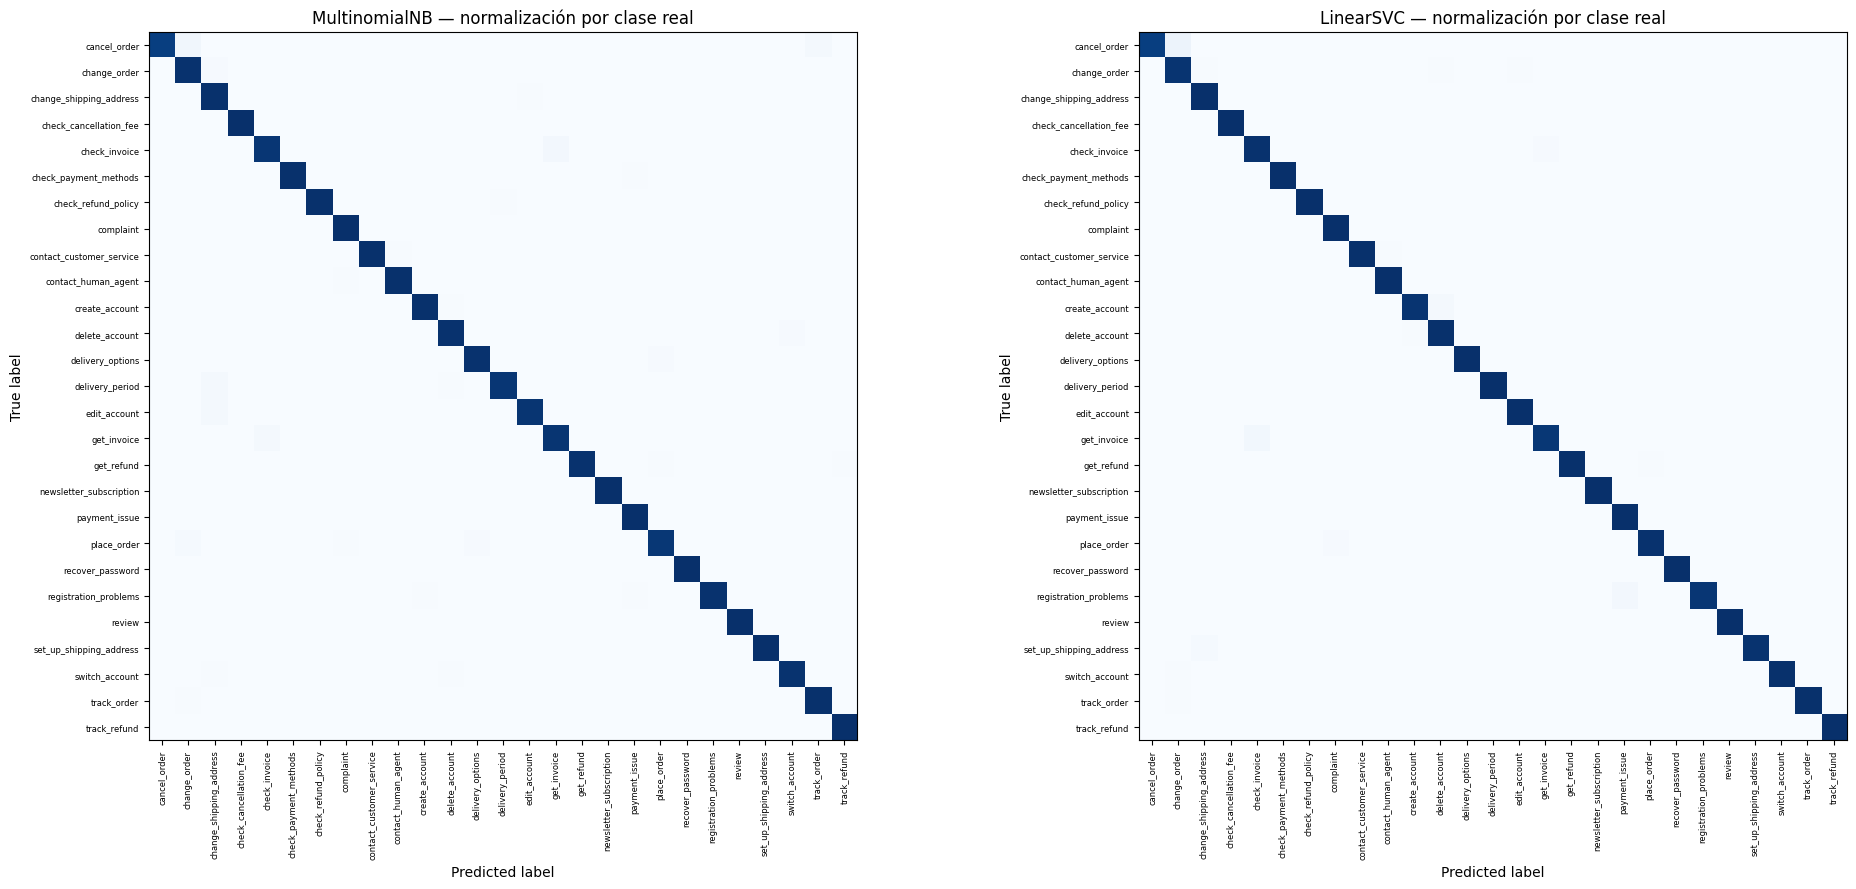

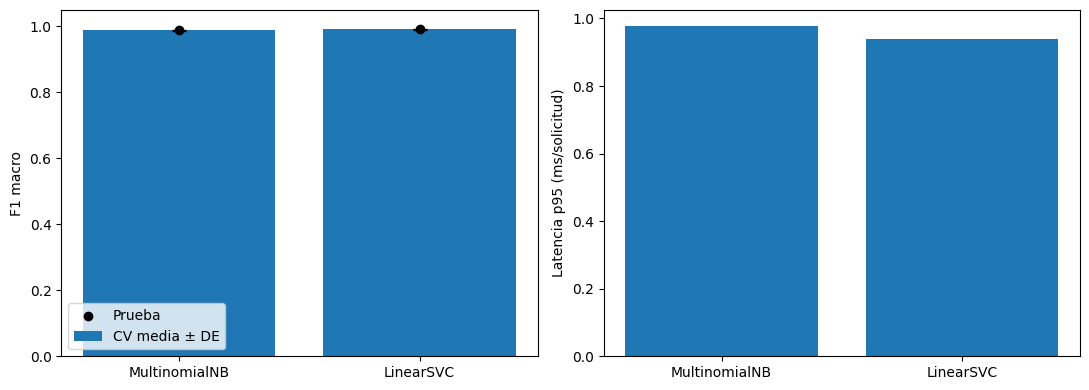

Modelo recomendado por CV: LinearSVC
Casos con algún error: 62


,source_row,text_clean,intent_clean,category,prediction_MultinomialNB,prediction_LinearSVC
4892,4892,i'm trying to fgind my bills from entity,check_invoice,INVOICE,get_invoice,get_invoice
16083,16083,refunding entity dollars,get_refund,REFUND,track_refund,get_refund
13883,13883,could you tell me about shipping periods?,delivery_period,DELIVERY,change_shipping_address,delivery_period
19186,19186,order anitem,place_order,ORDER,change_order,place_order
15729,15729,gedtting bill from entity,get_invoice,INVOICE,check_invoice,check_invoice
511,511,problems with cnceling purchase entity,cancel_order,ORDER,cancel_order,change_order
4431,4431,need to chek my bill #85632 how to do it,check_invoice,INVOICE,get_invoice,check_invoice
21376,21376,need help to report problems with a registratoon,registration_problems,ACCOUNT,payment_issue,payment_issue
24415,24415,would it be possible to sitch to the bloody en...,switch_account,ACCOUNT,delete_account,switch_account
21212,21212,can i inform of rwgistration errors,registration_problems,ACCOUNT,registration_problems,payment_issue


Confusiones más frecuentes de MultinomialNB


,,Casos
intent_clean,prediction_MultinomialNB,
check_invoice,get_invoice,5
delivery_period,change_shipping_address,4
get_invoice,check_invoice,4
edit_account,change_shipping_address,3
place_order,change_order,3


Confusiones más frecuentes de LinearSVC


,,Casos
intent_clean,prediction_LinearSVC,
cancel_order,change_order,5
registration_problems,payment_issue,5
get_invoice,check_invoice,5
create_account,delete_account,3
set_up_shipping_address,change_shipping_address,3


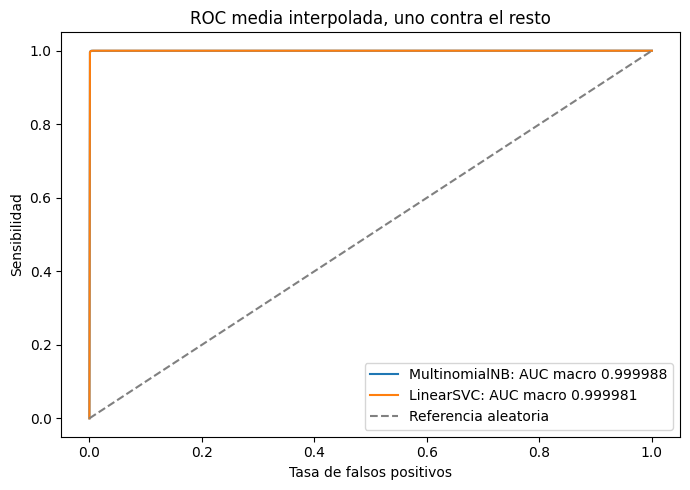

AUC macro = media de las 27 AUC binarias; la curva es una interpolación visual.
SVM usa márgenes sin convertirlos en probabilidades; Naive Bayes usa predict_proba.


In [10]:
winner = results.sort_values(['cv_f1_mean','model'],ascending=[False,True]).iloc[0]['model']
labels=sorted(y_test.unique())
fig,axes=plt.subplots(1,2,figsize=(20,9))
for ax,name in zip(axes,specs):
    ConfusionMatrixDisplay.from_predictions(y_test,predictions[name],labels=labels,normalize='true',
        ax=ax,xticks_rotation=90,include_values=False,colorbar=False,cmap='Blues')
    ax.set_title(name+' — normalización por clase real');ax.tick_params(labelsize=6)
fig.tight_layout();fig.savefig(REPORTS/'confusion_matrices.png',dpi=160,bbox_inches='tight');plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].bar(results.model,results.cv_f1_mean,yerr=results.cv_f1_std,capsize=5,label='CV media ± DE')
axes[0].scatter(results.model,results.test_f1_macro,color='black',label='Prueba');axes[0].set_ylim(0,1.05)
axes[0].set_ylabel('F1 macro');axes[0].legend()
axes[1].bar(results.model,results.latency_p95_ms);axes[1].set_ylabel('Latencia p95 (ms/solicitud)')
fig.tight_layout();fig.savefig(REPORTS/'comparison.png',dpi=160);plt.show()
errors=test[['source_row','text_clean','intent_clean','category']].copy()
for name in specs:errors['prediction_'+name]=predictions[name]
errors=errors.loc[np.logical_or.reduce([predictions[name]!=y_test.to_numpy() for name in specs])]
errors.to_csv(REPORTS/'errors.csv',index=False)
print('Modelo recomendado por CV:',winner)
print('Casos con algún error:',len(errors));display(errors.head(10))
for name in specs:
    wrong=errors.loc[errors['prediction_'+name]!=errors.intent_clean]
    print('Confusiones más frecuentes de',name)
    display(wrong.groupby(['intent_clean','prediction_'+name]).size().sort_values(ascending=False).head(5).to_frame('Casos'))

fig,ax=plt.subplots(figsize=(7,5))
for name,(classes,scores) in scores_by_model.items():
    grid_fpr=np.linspace(0,1,1001); tprs=[]
    for j,label in enumerate(classes):
        fpr,tpr,_=roc_curve((y_test.to_numpy()==label).astype(int),scores[:,j])
        tprs.append(np.interp(grid_fpr,fpr,tpr))
    mean_tpr=np.mean(tprs,axis=0);mean_tpr[0]=0;mean_tpr[-1]=1
    auc_value=results.set_index('model').loc[name,'test_roc_auc_macro_ovr']
    ax.plot(grid_fpr,mean_tpr,label=f'{name}: AUC macro {auc_value:.6f}')
ax.plot([0,1],[0,1],'--',color='grey',label='Referencia aleatoria')
ax.set(xlabel='Tasa de falsos positivos',ylabel='Sensibilidad',title='ROC media interpolada, uno contra el resto')
ax.legend();fig.tight_layout();fig.savefig(REPORTS/'roc_macro.png',dpi=160);plt.show()
print('AUC macro = media de las 27 AUC binarias; la curva es una interpolación visual.')
print('SVM usa márgenes sin convertirlos en probabilidades; Naive Bayes usa predict_proba.')


## 8 Análisis estadístico básico
Se reporta media y desviación estándar de F1 macro de los folds. Además, se compara la exactitud sobre los mismos tickets de prueba con McNemar exacta (binomial sobre pares discordantes), y se calcula un intervalo bootstrap pareado del 95 % para su diferencia. No se usa una prueba t ingenua sobre folds solapados.

El remuestreo presupone observaciones independientes. El origen sintético y las posibles paráfrasis limitan esa suposición; se interpreta como evidencia exploratoria y no como garantía de superioridad en producción. No se conoce el identificador de plantilla original para separar todas las familias de paráfrasis.


In [11]:
names=list(specs)
a=(predictions[names[0]]==y_test.to_numpy()).astype(int)
b=(predictions[names[1]]==y_test.to_numpy()).astype(int)
only_a=int(((a==1)&(b==0)).sum());only_b=int(((a==0)&(b==1)).sum())
p_value=float(binomtest(only_a,only_a+only_b,p=.5).pvalue) if only_a+only_b else 1.
rng=np.random.default_rng(SEED)
delta=a-b
boot=np.array([rng.choice(delta,size=len(delta),replace=True).mean() for _ in range(2000)])
stats={'comparison':names[0]+' menos '+names[1],'accuracy_difference':float(delta.mean()),
       'bootstrap_95_low':float(np.percentile(boot,2.5)),'bootstrap_95_high':float(np.percentile(boot,97.5)),
       'only_first_correct':only_a,'only_second_correct':only_b,'mcnemar_exact_p':p_value,
       'interpretation':'Exploratorio; datos sintéticos, posible dependencia entre paráfrasis.'}
save_json(stats,REPORTS/'statistics.json');display(pd.DataFrame([stats]))
print(f'McNemar exacta: p={p_value:.4f}. '+('No se rechaza igualdad de exactitud al nivel del 5 %.' if p_value>=.05 else 'Se rechaza igualdad de exactitud al nivel del 5 %, bajo los supuestos de la prueba.'))
print('Esta comparación evalúa exactitud, mientras que la selección del modelo utiliza F1 macro de validación.')
with mlflow.start_run(run_name='comparacion_estadistica') as comparison_run:
    mlflow.set_tags({'batch_id':BATCH_ID,'kind':'comparison'})
    mlflow.log_metrics({k:v for k,v in stats.items() if isinstance(v,(int,float))})
    mlflow.log_dict(stats,'statistics.json')
    mlflow.log_artifact(str(REPORTS/'model_comparison.csv'))
    for name in ['confusion_matrices.png','comparison.png','errors.csv','roc_macro.png','environment.json','provenance.json']:mlflow.log_artifact(str(REPORTS/name))


,comparison,accuracy_difference,bootstrap_95_low,bootstrap_95_high,only_first_correct,only_second_correct,mcnemar_exact_p,interpretation
0,MultinomialNB menos LinearSVC,-0.002707,-0.005205,0.0,16,29,0.072454,"Exploratorio; datos sintéticos, posible depend..."


McNemar exacta: p=0.0725. No se rechaza igualdad de exactitud al nivel del 5 %.
Esta comparación evalúa exactitud, mientras que la selección del modelo utiliza F1 macro de validación.


## 9 Interpretación y deuda técnica
Los resultados de prueba describen este conjunto reservado; no deben utilizarse para reconfigurar la búsqueda y volver a presentar la misma prueba como independiente.

| Deuda o riesgo | Acción propuesta | Evidencia o seguimiento |
|---|---|---|
| Datos sintéticos en inglés frente a NovaMarket en español | Obtener tickets reales anonimizados y etiquetados; evaluación externa | F1 macro, exactitud y errores por intención/idioma |
| Paráfrasis o plantillas relacionadas | Solicitar identificadores de familia y evaluar por grupos | Comparación con partición por familia |
| Dependencias y configuración | Versiones, manifiesto, Git y Pipeline completo | Hashes, commit y run_id |
| Drift y nuevas intenciones | Monitorear distribución y calidad con etiquetas humanas | Revisión si enrutamiento real baja del 90 %, umbral inicial de fase 1 |
| Datos personales | Ampliar controles y auditoría antes de operar | Incidentes y muestras revisadas |
| Escalamiento humano | Diseñar abstención y validar un umbral con conjunto separado | Cobertura y error de casos aceptados; no usar márgenes SVM como probabilidades |
| Ahorros y auto-resolución no medidos | Piloto operativo antes de actualizar ROI | FRT, AHT, CSAT, costos y resolución efectiva |

No se despliega el prototipo ni se promete auto-resolución a partir de sus predicciones. La latencia medida corresponde únicamente al Pipeline en CPU y excluye LLM, RAG, red y CRM.


In [12]:
selected=results.set_index('model').loc[winner]
conclusion=(f'El modelo seleccionado por validación cruzada fue {winner}, con F1 macro promedio '
 f'{selected.cv_f1_mean:.4f} y desviación estándar {selected.cv_f1_std:.4f}. En el conjunto de prueba obtuvo '
 f'F1 macro {selected.test_f1_macro:.4f} y exactitud {selected.test_accuracy:.4f}. '
 f'La preparación conservó {len(clean):,} solicitudes de {len(df_original):,} originales. '
 f'La prueba exploratoria de McNemar obtuvo p={p_value:.4f}; '
 + ('no se detectó una diferencia de exactitud concluyente al nivel del 5 %. ' if p_value>=.05 else 'se detectó una diferencia de exactitud al nivel del 5 %, condicionada a los supuestos de independencia. ')
 +
 'La recomendación se limita al prototipo de intenciones en inglés. No demuestra la meta de enrutamiento de NovaMarket '
 'ni los ahorros financieros de fase 1. Se requiere validación externa en español, revisión por intención y controles '
 'de datos personales antes de considerar su operación.')
print(conclusion)
(REPORTS/'conclusion.md').write_text('# Conclusión experimental\n\n'+conclusion,encoding='utf-8')
summary={'recommended_model':winner,'quality':quality,'statistics':stats,'models':records,'baseline':baseline}
save_json(summary,REPORTS/'summary.json')


El modelo seleccionado por validación cruzada fue LinearSVC, con F1 macro promedio 0.9919 y desviación estándar 0.0013. En el conjunto de prueba obtuvo F1 macro 0.9927 y exactitud 0.9931. La preparación conservó 24,014 solicitudes de 26,872 originales. La prueba exploratoria de McNemar obtuvo p=0.0725; no se detectó una diferencia de exactitud concluyente al nivel del 5 %. La recomendación se limita al prototipo de intenciones en inglés. No demuestra la meta de enrutamiento de NovaMarket ni los ahorros financieros de fase 1. Se requiere validación externa en español, revisión por intención y controles de datos personales antes de considerar su operación.


## 10 Auditoría de MLflow e inferencia
Se consultan exactamente los run_id del lote actual, se exigen 15 ejecuciones finalizadas (dos padres, doce candidatos y una comparación), parámetros y métricas persistidos. Se descarga un artefacto por modelo y se compara byte a byte. Se recargan **ambos modelos desde MLflow** y se comparan todas sus predicciones con las de la evaluación. La prueba inicial de configuración es un experimento separado; no se contabiliza como entrenamiento.

Las bases SQLite y el almacén de artefactos deben conservar la ubicación absoluta de trabajo. El ZIP de entrega permite reproducir el programa; no es una copia portátil de la base MLflow. En Colab no hace falta publicar un túnel: la consulta por API y sus tablas son evidencia real.


In [13]:
expected_ids=[r['run_id'] for r in records]+[comparison_run.info.run_id]
runs=mlflow.search_runs(experiment_ids=[EXPERIMENT_ID],filter_string=f"tags.batch_id = '{BATCH_ID}'",max_results=100)
assert len(runs)==15 and set(expected_ids)<=set(runs.run_id)
assert (runs.status=='FINISHED').all()
assert (runs['tags.kind']=='candidate').sum()==12
runs.to_csv(REPORTS/'mlflow_runs.csv',index=False)
checks=[]
for record in records:
    name=record['model']; persisted=client.get_run(record['run_id'])
    assert persisted.data.params['dataset_sha256']==manifest['processed_sha256']
    assert persisted.data.params['folds_sha256']==manifest['folds_sha256']
    for metric in ['accuracy','precision_macro','recall_macro','f1_macro','roc_auc_macro_ovr']:
        assert np.isclose(persisted.data.metrics['test_'+metric],record['test_'+metric],rtol=0,atol=1e-12)
    downloaded=client.download_artifacts(record['run_id'],f'{name}_grid.csv',str(download_dir))
    assert sha256(downloaded)==sha256(REPORTS/f'{name}_grid.csv')
    restored=mlflow.sklearn.load_model(model_uris[name])
    assert np.array_equal(restored.predict(X_test),predictions[name])
    local=joblib.load(MODELS/f'{name}.joblib')
    assert np.array_equal(local.predict(X_test),predictions[name])
    checks.append({'model':name,'run_id':record['run_id'],'model_uri':model_uris[name],
        'status':persisted.info.status,'params':dict(persisted.data.params),'metrics':dict(persisted.data.metrics),
        'artifacts':[a.path for a in client.list_artifacts(record['run_id'])],
        'downloaded_grid_sha256':sha256(downloaded),'mlflow_predictions_equal':True,'joblib_predictions_equal':True})
evidence={'batch_id':BATCH_ID,'experiment_id':EXPERIMENT_ID,'training_runs':15,
          'configuration_run':control.info.run_id,'models':checks,'all_runs_finished':True}
save_json(evidence,REPORTS/'mlflow_verificacion.json')
with mlflow.start_run(run_id=comparison_run.info.run_id):
    mlflow.log_artifact(str(REPORTS/'mlflow_verificacion.json'))
    mlflow.log_artifact(str(REPORTS/'mlflow_runs.csv'))
display(runs[['run_id','status','tags.mlflow.runName','tags.kind']])
print('VERIFICACIÓN COMPLETA: 15 runs de entrenamiento/comparación y ambos modelos recuperados desde MLflow.')
# Inferencia de demostración en el mismo idioma. No es una evaluación adicional.
texts=['I want to cancel my order','How can I get my invoice?','Where is my refund?']
selected_model=mlflow.sklearn.load_model(model_uris[winner])
intent_to_category=clean.groupby('intent_clean').category.first().to_dict()
intent_pred=selected_model.predict([clean_text(t) for t in texts])
display(pd.DataFrame({'solicitud':texts,'intencion':intent_pred,
                      'categoria':[intent_to_category[i] for i in intent_pred]}))


,run_id,status,tags.mlflow.runName,tags.kind
0,70b7a5b64a774dab8af56bd89887f609,FINISHED,comparacion_estadistica,comparison
1,27fd20b1de0b4a4b922cffa11f011fa6,FINISHED,LinearSVC_candidate_5,candidate
2,530aa3f2503f446f83391edadf8f12f6,FINISHED,LinearSVC_candidate_4,candidate
3,c1565472d10a4beea060b210df2d522f,FINISHED,LinearSVC_candidate_3,candidate
4,48298877fd774709a8cea2062757064f,FINISHED,LinearSVC_candidate_2,candidate
5,cfab2c6882f047a8b7603cd46f55d27f,FINISHED,LinearSVC_candidate_1,candidate
6,aac84627d1244e41a509301b683bd5c9,FINISHED,LinearSVC_candidate_0,candidate
7,4a8f35ae796448a58efd208d1292b082,FINISHED,LinearSVC,model
8,eb4b131e0faa48bcb9d307ce1cb5eff3,FINISHED,MultinomialNB_candidate_5,candidate
9,dd78dd7925694c69a345050e72eafbfb,FINISHED,MultinomialNB_candidate_4,candidate


VERIFICACIÓN COMPLETA: 15 runs de entrenamiento/comparación y ambos modelos recuperados desde MLflow.


,solicitud,intencion,categoria
0,I want to cancel my order,cancel_order,ORDER
1,How can I get my invoice?,get_invoice,INVOICE
2,Where is my refund?,track_refund,REFUND


## 11 Exportación y continuidad en GitHub
Se exportan `fuentes/datos_prep.py`, `fuentes/train.py`, requirements, README, CHANGELOG y un ZIP con las evidencias del lote. El script de entrenamiento contiene el mismo flujo de cálculo y auditoría que las celdas anteriores. La descarga del dataset está incluida, por lo que no hace falta distribuir el CSV.

Para la entrega, conserva este notebook como `fuentes/entrena.ipynb`. Si usas almacenamiento temporal de Colab, descarga el ZIP indicado al finalizar mediante el panel Archivos. El ZIP no incluye SQLite ni pretende mover el seguimiento a otra ruta. Con Drive, conserva la carpeta completa para consultar el mismo almacén.

El repositorio de continuidad ya es [Act5_GP](https://github.com/efrainkun-ai/Act5_GP). Los comandos `git add`, `git commit` y `git push` se ejecutan sobre tu copia de ese repositorio después de revisar los archivos generados; este notebook no modifica GitHub automáticamente.


In [15]:
TRAIN_SCRIPT = '#!/usr/bin/env python3\n"""Actividad 5. Ejecutar tras pip install -r requirements.txt. ACT5_ROOT cambia la salida."""\nimport sys, subprocess, os\nIN_COLAB=False\nfrom pathlib import Path\nimport re, json, hashlib, unicodedata, urllib.request, platform, time, shutil, uuid, importlib.util\nfrom datetime import datetime, timezone\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nimport joblib, sklearn, scipy, mlflow, mlflow.sklearn, sqlalchemy, packaging\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV\nfrom sklearn.naive_bayes import MultinomialNB\nfrom sklearn.svm import LinearSVC\nfrom sklearn.dummy import DummyClassifier\nfrom sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay, roc_auc_score, roc_curve\nfrom scipy.stats import binomtest\nfrom mlflow.tracking import MlflowClient\nfrom IPython.display import display\n\nGUARDAR_EN_DRIVE = True\nif IN_COLAB and GUARDAR_EN_DRIVE:\n    from google.colab import drive\n    drive.mount(\'/content/drive\')\n    ROOT = Path(\'/content/drive/MyDrive/Act5_GP/Actividad5\')\nelse:\n    ROOT = Path(os.environ.get(\'ACT5_ROOT\', str(Path.cwd() / \'Actividad5\')))\nROOT = ROOT.resolve()\nBATCH_ID = datetime.now(timezone.utc).strftime(\'%Y%m%dT%H%M%S\') + \'_\' + uuid.uuid4().hex[:8]\nRAW, PROCESSED, SOURCES = [ROOT / p for p in [\'datos/datos_ini\', \'datos/datos_limp\', \'fuentes\']]\nREPORTS = ROOT/\'evidencias\'/BATCH_ID\nMODELS = ROOT/\'modelos\'/BATCH_ID\nTRACKING = ROOT/\'.mlflow_local\'\nfor p in [RAW, PROCESSED, SOURCES, REPORTS, MODELS, TRACKING]: p.mkdir(parents=True, exist_ok=True)\nSEED = 42\nnp.random.seed(SEED)\ndef sha256(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()\ndef save_json(obj, path): Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding=\'utf-8\')\nversions = {name: module.__version__ for name,module in [(\'numpy\',np),(\'pandas\',pd),(\'scikit-learn\',sklearn),(\'scipy\',scipy),(\'matplotlib\',__import__(\'matplotlib\')),(\'mlflow\',mlflow),(\'joblib\',joblib),(\'sqlalchemy\',sqlalchemy),(\'packaging\',packaging)]}\n(ROOT/\'requirements_effective.txt\').write_text(\'\'.join(f\'{k}=={v}\\n\' for k,v in versions.items()))\nsave_json({\'python\':platform.python_version(),\'platform\':platform.platform(),\'packages\':versions}, REPORTS/\'environment.json\')\nprint(\'Directorio del proyecto:\', ROOT)\ndisplay(pd.DataFrame(versions.items(), columns=[\'Paquete\',\'Versión\']))\n\n# Guardar cada lote por separado impide mezclar evidencias de varias ejecuciones.\ntracking_uri = \'sqlite:///\' + str((TRACKING/\'mlflow.db\').resolve())\nmlflow.set_tracking_uri(tracking_uri)\nclient = MlflowClient(tracking_uri=tracking_uri)\ndef set_experiment_local(name):\n    exp = client.get_experiment_by_name(name)\n    if exp is None:\n        client.create_experiment(name, artifact_location=(TRACKING/\'artefactos\').as_uri())\n    else:\n        assert exp.lifecycle_stage == \'active\', \'El experimento está eliminado. Restaura o elige otro nombre.\'\n        assert exp.artifact_location == (TRACKING/\'artefactos\').as_uri(), \'El almacén cambió de ruta: usa una raíz nueva o conserva la ubicación original.\'\n    mlflow.set_experiment(name)\n    return client.get_experiment_by_name(name).experiment_id\n\n\nREPO = \'bitext/Bitext-customer-support-llm-chatbot-training-dataset\'\nREVISION = \'430d1a89bd93bd1fa23c16f29dd53e73f0087443\'\nCSV_NAME = \'Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv\'\nEXPECTED_SHA = \'6f81102b0100b97b8468eb04368033a23206bf1fde9d53500d5806ec1001a434\'\nBASE_URL = f\'https://huggingface.co/datasets/{REPO}/resolve/{REVISION}/\'\ndef download_verified(url, dest, expected=None):\n    dest=Path(dest)\n    if dest.exists():\n        if expected and sha256(dest)!=expected:\n            raise ValueError(f\'Archivo alterado: {dest}. Conserva una copia y revisa su procedencia.\')\n        return\n    temp=dest.with_suffix(dest.suffix+\'.part\')\n    try:\n        with urllib.request.urlopen(url,timeout=120) as response, temp.open(\'wb\') as f:\n            shutil.copyfileobj(response,f)\n        if expected and sha256(temp)!=expected: raise ValueError(\'SHA-256 inesperado en descarga\')\n        temp.replace(dest)\n    finally:\n        temp.unlink(missing_ok=True)\ndownload_verified(BASE_URL+CSV_NAME, RAW/CSV_NAME, EXPECTED_SHA)\ndownload_verified(BASE_URL+\'README.md\', RAW/\'README_fuente.md\')\n# La licencia se documenta por URL y declaración de la revisión fijada.\ndf_original = pd.read_csv(RAW/CSV_NAME, dtype=str)\nassert set(df_original.columns)=={\'instruction\',\'intent\',\'category\',\'flags\',\'response\'}\nassert len(df_original)==26872\nprint(\'Filas y columnas:\',df_original.shape)\nprint(\'Intenciones:\',df_original.intent.nunique(),\'Categorías:\',df_original.category.nunique())\ndisplay(df_original[[\'instruction\',\'intent\',\'category\']].head())\ndisplay(df_original.isna().sum().to_frame(\'Faltantes\'))\nsave_json({\'dataset\':REPO,\'revision\':REVISION,\'url\':BASE_URL+CSV_NAME,\'sha256\':EXPECTED_SHA,\n           \'source_card_sha256\':sha256(RAW/\'README_fuente.md\'),\'license\':\'CDLA Sharing 1.0\',\n           \'license_url\':\'https://cdla.dev/sharing-1-0/\'}, ROOT/\'datos/dataset.lock.json\')\n\n\nCLEANING_SOURCE = "import pandas as pd\\nimport re, unicodedata\\n\\ndef clean_text(value):\\n    if pd.isna(value): return \'\'\\n    text = unicodedata.normalize(\'NFKC\', str(value)).strip().lower()\\n    text = re.sub(r\'\\\\{\\\\{.*?\\\\}\\\\}\', \' entity \', text)\\n    text = re.sub(r\'[\\\\w.+-]+@[\\\\w.-]+\\\\.[a-z]{2,}\', \' email \', text)\\n    text = re.sub(r\'(?<!\\\\w)\\\\+?\\\\d[\\\\d ()-]{7,}\\\\d(?!\\\\w)\', \' phone \', text)\\n    return re.sub(r\'\\\\s+\', \' \', text).strip()\\n\\n"\n(SOURCES/\'datos_prep.py\').write_text(CLEANING_SOURCE,encoding=\'utf-8\')\nspec = importlib.util.spec_from_file_location("act5_datos_prep", SOURCES/"datos_prep.py")\nprep_module = importlib.util.module_from_spec(spec)\nspec.loader.exec_module(prep_module)\nclean_text = prep_module.clean_text\n\naudit = df_original.copy()\naudit.insert(0, \'source_row\', np.arange(len(audit)))\naudit[\'text_clean\'] = audit.instruction.map(clean_text)\naudit[\'intent_clean\'] = audit.intent.fillna(\'\').str.strip().str.lower()\naudit[\'text_sha256\'] = audit.text_clean.map(lambda s: hashlib.sha256(s.encode()).hexdigest())\naudit[\'exclusion_reason\'] = \'\'\ninvalid = audit.text_clean.eq(\'\') | audit.intent_clean.eq(\'\') | audit.category.fillna(\'\').str.strip().eq(\'\')\naudit.loc[invalid,\'exclusion_reason\'] = \'texto_o_etiqueta_vacios\'\nvalid = audit.loc[~invalid]\nconflicts = valid.groupby(\'text_sha256\').intent_clean.nunique()\nconflict_keys = set(conflicts[conflicts>1].index)\naudit.loc[~invalid & audit.text_sha256.isin(conflict_keys),\'exclusion_reason\'] = \'etiquetas_contradictorias\'\neligible = audit.exclusion_reason.eq(\'\')\nduplicates = audit.loc[eligible].duplicated(\'text_sha256\', keep=\'first\')\naudit.loc[duplicates[duplicates].index,\'exclusion_reason\'] = \'texto_duplicado\'\nclean = audit.loc[audit.exclusion_reason.eq(\'\'), [\'source_row\',\'text_clean\',\'text_sha256\',\'intent_clean\',\'category\',\'flags\']].copy()\nassert not clean.text_sha256.duplicated().any()\nassert clean.groupby(\'intent_clean\').category.nunique().max()==1\nassert clean.intent_clean.value_counts().min()>=10\nclean.to_csv(PROCESSED/\'tickets_clean_v1.csv\', index=False)\n# Auditoría completa: incluye registros conservados y descartados.\naudit[[\'source_row\',\'text_sha256\',\'intent_clean\',\'exclusion_reason\']].to_csv(REPORTS/\'audit_all_rows.csv\',index=False)\nquality = {\'raw_rows\':len(audit),\'clean_rows\':len(clean),\'excluded_rows\':len(audit)-len(clean),\n           \'exclusion_reasons\':audit.exclusion_reason.replace(\'\',\'conservado\').value_counts().to_dict(),\n           \'intents\':int(clean.intent_clean.nunique()),\'categories\':int(clean.category.nunique()),\n           \'missing_raw\':df_original.isna().sum().astype(int).to_dict(),\n           \'empty_raw\':{c:int(df_original[c].fillna(\'\').str.strip().eq(\'\').sum()) for c in df_original},\n           \'conflicting_texts\':len(conflict_keys)}\naudit[[\'source_row\',\'text_sha256\',\'intent_clean\',\'exclusion_reason\']].to_csv(PROCESSED/\'auditoria_v1.csv\',index=False)\nsave_json(quality,REPORTS/\'quality.json\')\ndisplay(pd.DataFrame(quality[\'exclusion_reasons\'].items(),columns=[\'Estado\',\'Filas\']))\nprint(\'Filas limpias:\',len(clean))\n\n\nfig, axes = plt.subplots(1,3,figsize=(18,6))\nclean.intent_clean.value_counts().sort_values().plot.barh(ax=axes[0],fontsize=7)\naxes[0].set_title(\'Distribución de intenciones\'); axes[0].set_xlabel(\'Solicitudes\')\naudit.text_clean.str.len().hist(bins=40,ax=axes[1],alpha=.55,label=\'Original normalizado\')\nclean.text_clean.str.len().hist(bins=40,ax=axes[1],alpha=.55,label=\'Después de deduplicar\')\naxes[1].set_title(\'Longitud del texto\'); axes[1].set_xlabel(\'Caracteres\'); axes[1].legend()\npd.Series(quality[\'exclusion_reasons\']).plot.bar(ax=axes[2],rot=30)\naxes[2].set_title(\'Estado de los registros\'); axes[2].set_ylabel(\'Filas\')\nfig.tight_layout(); fig.savefig(REPORTS/\'quality.png\',dpi=160,bbox_inches=\'tight\'); plt.show()\ncounts = clean.intent_clean.value_counts()\nprint(f\'Desbalance máximo/mínimo después de limpiar: {counts.max()/counts.min():.2f}.\')\nprint(\'Las exclusiones reducen redundancia exacta; no demuestran diversidad de plantillas ni cobertura real del negocio.\')\ndisplay(clean.assign(characters=clean.text_clean.str.len()).nlargest(5,\'characters\')[[\'text_clean\',\'intent_clean\',\'characters\']])\n\n\ntrain, test = train_test_split(clean,test_size=.2,random_state=SEED,stratify=clean.intent_clean)\nassert set(train.text_sha256).isdisjoint(set(test.text_sha256))\nsplit = pd.concat([train.assign(split=\'train\'),test.assign(split=\'test\')])[[\'source_row\',\'text_sha256\',\'split\']]\nsplit.to_csv(PROCESSED/\'split_v1.csv\',index=False)\nX_train, y_train = train.text_clean, train.intent_clean\nX_test, y_test = test.text_clean, test.intent_clean\nfolds=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(X_train,y_train))\nfold_rows=[]\nfor fold,(fit_idx,val_idx) in enumerate(folds):\n    assert set(train.iloc[fit_idx].text_sha256).isdisjoint(set(train.iloc[val_idx].text_sha256))\n    fold_rows.append(pd.DataFrame({\'source_row\':train.iloc[val_idx].source_row.to_numpy(),\n        \'text_sha256\':train.iloc[val_idx].text_sha256.to_numpy(),\'validation_fold\':fold}))\nfold_manifest=pd.concat(fold_rows,ignore_index=True)\nassert len(fold_manifest)==len(train) and not fold_manifest.source_row.duplicated().any()\nfold_manifest.to_csv(PROCESSED/\'folds_v1.csv\',index=False)\nmanifest={\'dataset\':REPO,\'revision\':REVISION,\'license\':\'cdla-sharing-1.0\',\'raw_sha256\':EXPECTED_SHA,\n \'processed_sha256\':sha256(PROCESSED/\'tickets_clean_v1.csv\'),\'split_sha256\':sha256(PROCESSED/\'split_v1.csv\'),\n \'folds_sha256\':sha256(PROCESSED/\'folds_v1.csv\'),\'cleaning_code_sha256\':sha256(SOURCES/\'datos_prep.py\'),\n \'seed\':SEED,\'test_size\':.2,\'cleaning_version\':\'v1\',\'target\':\'intent_clean\',\'predictor\':\'text_clean\',\n \'train_rows\':len(train),\'test_rows\':len(test),\'folds\':5}\nsave_json(manifest,ROOT/\'datos/preparacion_v1.json\')\nsave_json(manifest,REPORTS/\'dataset_manifest_v1.json\')\ngit_commit=\'sin_commit\'\nif shutil.which(\'git\'):\n    proc=subprocess.run([\'git\',\'-C\',str(ROOT),\'rev-parse\',\'HEAD\'],capture_output=True,text=True)\n    if proc.returncode==0: git_commit=proc.stdout.strip()\n# Los hashes versionan también ejecuciones sin un repositorio Git inicializado.\nsave_json({\'git_commit_observado\':git_commit,\'batch_id\':BATCH_ID,\'manifest\':manifest},REPORTS/\'provenance.json\')\nprint(\'Train:\',len(train),\'Test:\',len(test),\'Folds:\',len(folds),\'Commit observado:\',git_commit)\nprint(\'No hay textos normalizados idénticos entre entrenamiento y prueba.\')\n\n\nset_experiment_local(\'Act5_GP_Configuracion_Integrado\')\ncontrol_file=REPORTS/\'mlflow_control.txt\'\ncontrol_file.write_text(\'Actividad 5: verificación de persistencia de MLflow.\\n\',encoding=\'utf-8\')\nwith mlflow.start_run(run_name=\'verificacion_\'+BATCH_ID) as control_run:\n    mlflow.set_tags({\'batch_id\':BATCH_ID,\'kind\':\'configuration\'})\n    mlflow.log_param(\'proyecto\',\'AI-SupportAssist\')\n    mlflow.log_metric(\'valor_control\',1.0)\n    mlflow.log_artifact(str(control_file))\n    mlflow.log_artifact(str(REPORTS/\'environment.json\'))\ncontrol=client.get_run(control_run.info.run_id)\ndownload_dir=REPORTS/\'descargas_verificadas\'\ndownload_dir.mkdir(exist_ok=True)\ncontrol_download=client.download_artifacts(control.info.run_id,\'mlflow_control.txt\',str(download_dir))\ncontrols={\'finished\':control.info.status==\'FINISHED\',\'parametro\':control.data.params.get(\'proyecto\')==\'AI-SupportAssist\',\n          \'metrica\':control.data.metrics.get(\'valor_control\')==1.0,\'artefacto\':sha256(control_download)==sha256(control_file)}\nassert all(controls.values()),controls\nsave_json({\'run_id\':control.info.run_id,\'controles\':controls},REPORTS/\'mlflow_configuracion.json\')\nprint(\'MLflow configurado y persistencia validada:\',controls)\n\n\nscoring={\'f1_macro\':\'f1_macro\',\'accuracy\':\'accuracy\'}\nspecs = {\n \'MultinomialNB\':(MultinomialNB(),{\'tfidf__ngram_range\':[(1,1),(1,2)],\'clf__alpha\':[.1,.5,1.]}),\n \'LinearSVC\':(LinearSVC(random_state=SEED,max_iter=10000),{\'tfidf__ngram_range\':[(1,1),(1,2)],\'clf__C\':[.5,1.,2.]})}\nexperiment_name=\'Actividad5_AI_SupportAssist_Intent_v2\'\nEXPERIMENT_ID=set_experiment_local(experiment_name)\nmodel_uris={}\nscores_by_model={}\ndef metrics(y,p):\n    return {\'accuracy\':accuracy_score(y,p),\'precision_macro\':precision_score(y,p,average=\'macro\',zero_division=0),\n            \'recall_macro\':recall_score(y,p,average=\'macro\',zero_division=0),\'f1_macro\':f1_score(y,p,average=\'macro\',zero_division=0)}\ndummy=DummyClassifier(strategy=\'most_frequent\').fit(np.zeros((len(y_train),1)),y_train)\nbaseline=metrics(y_test,dummy.predict(np.zeros((len(y_test),1))))\nsave_json(baseline,REPORTS/\'baseline.json\')\nsearches, predictions, records = {}, {}, []\nfor name,(clf,grid_params) in specs.items():\n    print(\'Entrenando:\',name,flush=True)\n    pipe=Pipeline([(\'tfidf\',TfidfVectorizer(min_df=2,max_features=20000,sublinear_tf=True)),(\'clf\',clf)])\n    with mlflow.start_run(run_name=name) as run:\n        mlflow.set_tags({\'batch_id\':BATCH_ID,\'kind\':\'model\'})\n        mlflow.set_tags({\'dataset_revision\':REVISION,\'git_commit\':git_commit,\'cleaning_version\':\'v1\',\'scope\':\'synthetic_english_prototype\'})\n        mlflow.log_params({\'seed\':SEED,\'folds\':5,\'selection_metric\':\'f1_macro\',\'dataset_sha256\':manifest[\'processed_sha256\'],\n                           \'split_sha256\':manifest[\'split_sha256\'],\'folds_sha256\':manifest[\'folds_sha256\'],\'train_rows\':len(train),\'test_rows\':len(test),\'max_features\':20000,\'min_df\':2})\n        start=time.perf_counter()\n        grid=GridSearchCV(pipe,grid_params,cv=folds,scoring=scoring,refit=\'f1_macro\',n_jobs=1,return_train_score=True,error_score=\'raise\')\n        grid.fit(X_train,y_train)\n        fit_seconds=time.perf_counter()-start\n        cv_results=pd.DataFrame(grid.cv_results_)\n        cv_results.to_csv(REPORTS/f\'{name}_grid.csv\',index=False)\n        for idx,row in cv_results.iterrows():\n            with mlflow.start_run(run_name=f\'{name}_candidate_{idx}\',nested=True):\n                mlflow.set_tags({\'batch_id\':BATCH_ID,\'kind\':\'candidate\'})\n                mlflow.log_params({k:str(v) for k,v in row[\'params\'].items()})\n                mlflow.log_metrics({\'cv_f1_macro_mean\':row[\'mean_test_f1_macro\'],\'cv_f1_macro_std\':row[\'std_test_f1_macro\'],\n                                    \'cv_accuracy_mean\':row[\'mean_test_accuracy\'],\'mean_fit_seconds\':row[\'mean_fit_time\']})\n                for fold in range(5): mlflow.log_metric(f\'fold_{fold}_f1_macro\',row[f\'split{fold}_test_f1_macro\'])\n        best=grid.best_estimator_\n        pred=best.predict(X_test)\n        predictions[name]=pred\n        classes=best.named_steps[\'clf\'].classes_\n        assert set(classes)==set(y_test.unique())\n        scores=best.predict_proba(X_test) if hasattr(best,\'predict_proba\') else best.decision_function(X_test)\n        assert scores.shape==(len(y_test),len(classes))\n        aucs=[roc_auc_score((y_test.to_numpy()==label).astype(int),scores[:,j]) for j,label in enumerate(classes)]\n        scores_by_model[name]=(classes,scores)\n        pd.DataFrame({\'intent\':classes,\'roc_auc_ovr\':aucs}).to_csv(REPORTS/f\'{name}_auc_por_clase.csv\',index=False)\n        train_metrics=metrics(y_train,best.predict(X_train)); test_metrics=metrics(y_test,pred)\n        test_metrics[\'roc_auc_macro_ovr\']=float(np.mean(aucs))\n        # Latencia por solicitud tras calentamiento; depende del hardware y no incluye red ni CRM.\n        samples=X_test.iloc[:min(200,len(X_test))].tolist(); best.predict(samples[:5])\n        lat=[]\n        for text in samples:\n            start=time.perf_counter(); best.predict([text]);lat.append((time.perf_counter()-start)*1000)\n        row={\'model\':name,\'cv_f1_mean\':grid.best_score_,\'cv_f1_std\':float(cv_results.iloc[grid.best_index_][\'std_test_f1_macro\']),\n             **{\'test_\'+k:v for k,v in test_metrics.items()},\'train_f1_macro\':train_metrics[\'f1_macro\'],\n             \'search_seconds\':fit_seconds,\'latency_p50_ms\':float(np.median(lat)),\'latency_p95_ms\':float(np.percentile(lat,95)),\n             \'run_id\':run.info.run_id,\'best_params\':str(grid.best_params_)}\n        mlflow.log_params({\'best_\'+k:str(v) for k,v in grid.best_params_.items()})\n        mlflow.log_metrics({k:v for k,v in row.items() if isinstance(v,(int,float))})\n        mlflow.log_dict(manifest,\'dataset_manifest.json\')\n        mlflow.log_artifact(str(REPORTS/f\'{name}_grid.csv\'))\n        mlflow.log_artifact(str(REPORTS/\'quality.json\'))\n        mlflow.log_artifact(str(REPORTS/\'quality.png\'))\n        signature=mlflow.models.infer_signature(X_train.iloc[:3].to_numpy(),best.predict(X_train.iloc[:3]))\n        model_info=mlflow.sklearn.log_model(best,name=\'model\',signature=signature,input_example=X_train.iloc[:3].to_numpy())\n        model_uris[name]=model_info.model_uri\n        row[\'model_uri\']=model_info.model_uri\n        joblib.dump(best,MODELS/f\'{name}.joblib\')\n        row[\'model_bytes\']=(MODELS/f\'{name}.joblib\').stat().st_size\n        mlflow.log_metric(\'model_bytes\',row[\'model_bytes\'])\n        pd.DataFrame(classification_report(y_test,pred,output_dict=True,zero_division=0)).T.to_csv(REPORTS/f\'{name}_classification_report.csv\')\n        for file in [f\'{name}_classification_report.csv\',f\'{name}_auc_por_clase.csv\',\'environment.json\']:\n            mlflow.log_artifact(str(REPORTS/file))\n        mlflow.log_artifact(str(SOURCES/\'datos_prep.py\'),artifact_path=\'fuentes\')\n        records.append(row); searches[name]=grid\nresults=pd.DataFrame(records)\nresults.to_csv(REPORTS/\'model_comparison.csv\',index=False)\ndisplay(results.drop(columns=[\'run_id\',\'best_params\',\'model_uri\']))\nprint(\'Baseline de clase mayoritaria:\',baseline)\n\n\nwinner = results.sort_values([\'cv_f1_mean\',\'model\'],ascending=[False,True]).iloc[0][\'model\']\nlabels=sorted(y_test.unique())\nfig,axes=plt.subplots(1,2,figsize=(20,9))\nfor ax,name in zip(axes,specs):\n    ConfusionMatrixDisplay.from_predictions(y_test,predictions[name],labels=labels,normalize=\'true\',\n        ax=ax,xticks_rotation=90,include_values=False,colorbar=False,cmap=\'Blues\')\n    ax.set_title(name+\' — normalización por clase real\');ax.tick_params(labelsize=6)\nfig.tight_layout();fig.savefig(REPORTS/\'confusion_matrices.png\',dpi=160,bbox_inches=\'tight\');plt.show()\nfig,axes=plt.subplots(1,2,figsize=(11,4))\naxes[0].bar(results.model,results.cv_f1_mean,yerr=results.cv_f1_std,capsize=5,label=\'CV media ± DE\')\naxes[0].scatter(results.model,results.test_f1_macro,color=\'black\',label=\'Prueba\');axes[0].set_ylim(0,1.05)\naxes[0].set_ylabel(\'F1 macro\');axes[0].legend()\naxes[1].bar(results.model,results.latency_p95_ms);axes[1].set_ylabel(\'Latencia p95 (ms/solicitud)\')\nfig.tight_layout();fig.savefig(REPORTS/\'comparison.png\',dpi=160);plt.show()\nerrors=test[[\'source_row\',\'text_clean\',\'intent_clean\',\'category\']].copy()\nfor name in specs:errors[\'prediction_\'+name]=predictions[name]\nerrors=errors.loc[np.logical_or.reduce([predictions[name]!=y_test.to_numpy() for name in specs])]\nerrors.to_csv(REPORTS/\'errors.csv\',index=False)\nprint(\'Modelo recomendado por CV:\',winner)\nprint(\'Casos con algún error:\',len(errors));display(errors.head(10))\nfor name in specs:\n    wrong=errors.loc[errors[\'prediction_\'+name]!=errors.intent_clean]\n    print(\'Confusiones más frecuentes de\',name)\n    display(wrong.groupby([\'intent_clean\',\'prediction_\'+name]).size().sort_values(ascending=False).head(5).to_frame(\'Casos\'))\n\nfig,ax=plt.subplots(figsize=(7,5))\nfor name,(classes,scores) in scores_by_model.items():\n    grid_fpr=np.linspace(0,1,1001); tprs=[]\n    for j,label in enumerate(classes):\n        fpr,tpr,_=roc_curve((y_test.to_numpy()==label).astype(int),scores[:,j])\n        tprs.append(np.interp(grid_fpr,fpr,tpr))\n    mean_tpr=np.mean(tprs,axis=0);mean_tpr[0]=0;mean_tpr[-1]=1\n    auc_value=results.set_index(\'model\').loc[name,\'test_roc_auc_macro_ovr\']\n    ax.plot(grid_fpr,mean_tpr,label=f\'{name}: AUC macro {auc_value:.6f}\')\nax.plot([0,1],[0,1],\'--\',color=\'grey\',label=\'Referencia aleatoria\')\nax.set(xlabel=\'Tasa de falsos positivos\',ylabel=\'Sensibilidad\',title=\'ROC media interpolada, uno contra el resto\')\nax.legend();fig.tight_layout();fig.savefig(REPORTS/\'roc_macro.png\',dpi=160);plt.show()\nprint(\'AUC macro = media de las 27 AUC binarias; la curva es una interpolación visual.\')\nprint(\'SVM usa márgenes sin convertirlos en probabilidades; Naive Bayes usa predict_proba.\')\n\n\nnames=list(specs)\na=(predictions[names[0]]==y_test.to_numpy()).astype(int)\nb=(predictions[names[1]]==y_test.to_numpy()).astype(int)\nonly_a=int(((a==1)&(b==0)).sum());only_b=int(((a==0)&(b==1)).sum())\np_value=float(binomtest(only_a,only_a+only_b,p=.5).pvalue) if only_a+only_b else 1.\nrng=np.random.default_rng(SEED)\ndelta=a-b\nboot=np.array([rng.choice(delta,size=len(delta),replace=True).mean() for _ in range(2000)])\nstats={\'comparison\':names[0]+\' menos \'+names[1],\'accuracy_difference\':float(delta.mean()),\n       \'bootstrap_95_low\':float(np.percentile(boot,2.5)),\'bootstrap_95_high\':float(np.percentile(boot,97.5)),\n       \'only_first_correct\':only_a,\'only_second_correct\':only_b,\'mcnemar_exact_p\':p_value,\n       \'interpretation\':\'Exploratorio; datos sintéticos, posible dependencia entre paráfrasis.\'}\nsave_json(stats,REPORTS/\'statistics.json\');display(pd.DataFrame([stats]))\nprint(f\'McNemar exacta: p={p_value:.4f}. \'+(\'No se rechaza igualdad de exactitud al nivel del 5 %.\' if p_value>=.05 else \'Se rechaza igualdad de exactitud al nivel del 5 %, bajo los supuestos de la prueba.\'))\nprint(\'Esta comparación evalúa exactitud, mientras que la selección del modelo utiliza F1 macro de validación.\')\nwith mlflow.start_run(run_name=\'comparacion_estadistica\') as comparison_run:\n    mlflow.set_tags({\'batch_id\':BATCH_ID,\'kind\':\'comparison\'})\n    mlflow.log_metrics({k:v for k,v in stats.items() if isinstance(v,(int,float))})\n    mlflow.log_dict(stats,\'statistics.json\')\n    mlflow.log_artifact(str(REPORTS/\'model_comparison.csv\'))\n    for name in [\'confusion_matrices.png\',\'comparison.png\',\'errors.csv\',\'roc_macro.png\',\'environment.json\',\'provenance.json\']:mlflow.log_artifact(str(REPORTS/name))\n\n\nselected=results.set_index(\'model\').loc[winner]\nconclusion=(f\'El modelo seleccionado por validación cruzada fue {winner}, con F1 macro promedio \'\n f\'{selected.cv_f1_mean:.4f} y desviación estándar {selected.cv_f1_std:.4f}. En el conjunto de prueba obtuvo \'\n f\'F1 macro {selected.test_f1_macro:.4f} y exactitud {selected.test_accuracy:.4f}. \'\n f\'La preparación conservó {len(clean):,} solicitudes de {len(df_original):,} originales. \'\n f\'La prueba exploratoria de McNemar obtuvo p={p_value:.4f}; \'\n + (\'no se detectó una diferencia de exactitud concluyente al nivel del 5 %. \' if p_value>=.05 else \'se detectó una diferencia de exactitud al nivel del 5 %, condicionada a los supuestos de independencia. \')\n +\n \'La recomendación se limita al prototipo de intenciones en inglés. No demuestra la meta de enrutamiento de NovaMarket \'\n \'ni los ahorros financieros de fase 1. Se requiere validación externa en español, revisión por intención y controles \'\n \'de datos personales antes de considerar su operación.\')\nprint(conclusion)\n(REPORTS/\'conclusion.md\').write_text(\'# Conclusión experimental\\n\\n\'+conclusion,encoding=\'utf-8\')\nsummary={\'recommended_model\':winner,\'quality\':quality,\'statistics\':stats,\'models\':records,\'baseline\':baseline}\nsave_json(summary,REPORTS/\'summary.json\')\n\n\nexpected_ids=[r[\'run_id\'] for r in records]+[comparison_run.info.run_id]\nruns=mlflow.search_runs(experiment_ids=[EXPERIMENT_ID],filter_string=f"tags.batch_id = \'{BATCH_ID}\'",max_results=100)\nassert len(runs)==15 and set(expected_ids)<=set(runs.run_id)\nassert (runs.status==\'FINISHED\').all()\nassert (runs[\'tags.kind\']==\'candidate\').sum()==12\nruns.to_csv(REPORTS/\'mlflow_runs.csv\',index=False)\nchecks=[]\nfor record in records:\n    name=record[\'model\']; persisted=client.get_run(record[\'run_id\'])\n    assert persisted.data.params[\'dataset_sha256\']==manifest[\'processed_sha256\']\n    assert persisted.data.params[\'folds_sha256\']==manifest[\'folds_sha256\']\n    for metric in [\'accuracy\',\'precision_macro\',\'recall_macro\',\'f1_macro\',\'roc_auc_macro_ovr\']:\n        assert np.isclose(persisted.data.metrics[\'test_\'+metric],record[\'test_\'+metric],rtol=0,atol=1e-12)\n    downloaded=client.download_artifacts(record[\'run_id\'],f\'{name}_grid.csv\',str(download_dir))\n    assert sha256(downloaded)==sha256(REPORTS/f\'{name}_grid.csv\')\n    restored=mlflow.sklearn.load_model(model_uris[name])\n    assert np.array_equal(restored.predict(X_test),predictions[name])\n    local=joblib.load(MODELS/f\'{name}.joblib\')\n    assert np.array_equal(local.predict(X_test),predictions[name])\n    checks.append({\'model\':name,\'run_id\':record[\'run_id\'],\'model_uri\':model_uris[name],\n        \'status\':persisted.info.status,\'params\':dict(persisted.data.params),\'metrics\':dict(persisted.data.metrics),\n        \'artifacts\':[a.path for a in client.list_artifacts(record[\'run_id\'])],\n        \'downloaded_grid_sha256\':sha256(downloaded),\'mlflow_predictions_equal\':True,\'joblib_predictions_equal\':True})\nevidence={\'batch_id\':BATCH_ID,\'experiment_id\':EXPERIMENT_ID,\'training_runs\':15,\n          \'configuration_run\':control.info.run_id,\'models\':checks,\'all_runs_finished\':True}\nsave_json(evidence,REPORTS/\'mlflow_verificacion.json\')\nwith mlflow.start_run(run_id=comparison_run.info.run_id):\n    mlflow.log_artifact(str(REPORTS/\'mlflow_verificacion.json\'))\n    mlflow.log_artifact(str(REPORTS/\'mlflow_runs.csv\'))\ndisplay(runs[[\'run_id\',\'status\',\'tags.mlflow.runName\',\'tags.kind\']])\nprint(\'VERIFICACIÓN COMPLETA: 15 runs de entrenamiento/comparación y ambos modelos recuperados desde MLflow.\')\n# Inferencia de demostración en el mismo idioma. No es una evaluación adicional.\ntexts=[\'I want to cancel my order\',\'How can I get my invoice?\',\'Where is my refund?\']\nselected_model=mlflow.sklearn.load_model(model_uris[winner])\nintent_to_category=clean.groupby(\'intent_clean\').category.first().to_dict()\nintent_pred=selected_model.predict([clean_text(t) for t in texts])\ndisplay(pd.DataFrame({\'solicitud\':texts,\'intencion\':intent_pred,\n                      \'categoria\':[intent_to_category[i] for i in intent_pred]}))\n'
REQUIREMENTS = 'mlflow==3.5.0\nscikit-learn==1.7.2\npandas==2.3.3\nnumpy==2.2.6\nscipy==1.16.3\nmatplotlib==3.10.7\njoblib==1.5.2\nSQLAlchemy==2.0.43\npackaging==25.0\nipython>=8,<10\n'
# Exportar soporte reproducible; esta celda se muestra contraída en Colab.
(SOURCES/'train.py').write_text(TRAIN_SCRIPT,encoding='utf-8')
(ROOT/'requirements.txt').write_text(REQUIREMENTS,encoding='utf-8')
readme='''# Actividad 5 · AI-SupportAssist
## Reproducción
En Colab: ejecutar fuentes/entrena.ipynb en CPU y en orden. El montaje de Drive es opcional.
En Python local: pip install -r requirements.txt y python fuentes/train.py.
ACT5_ROOT permite cambiar la carpeta de resultados. Guardar SQLite y artefactos en su ruta de trabajo.
## Datos
Bitext, revisión 430d1a89bd93bd1fa23c16f29dd53e73f0087443. Origen híbrido sintético en inglés.
Fuente: https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset
Licencia declarada CDLA Sharing 1.0: https://cdla.dev/sharing-1-0/
Los originales se obtienen por el script y se comprueban con SHA-256. Nunca son tickets reales de NovaMarket.
## Experimento
TF-IDF + MultinomialNB y LinearSVC. Seis configuraciones y cinco folds por modelo.
Selección por F1 macro de CV; prueba reservada del 20 %. ROC-AUC macro uno contra el resto.
Folds, manifiestos y código de limpieza se versionan por hashes. Evidencias por batch_id.
MLflow local: un run de configuración separado, 12 candidatos, 2 padres y 1 comparación.
McNemar y bootstrap pareados son exploratorios por posible dependencia entre paráfrasis.
## Archivos
Datos: datos/datos_ini y datos/datos_limp. Scripts: fuentes. Resultados: evidencias/<batch>.
Los modelos y el almacén completo se regeneran. El ZIP no traslada SQLite a otra ruta.
Repositorio de continuidad: https://github.com/efrainkun-ai/Act5_GP
Para publicar, subir notebook, scripts, requirements, README, CHANGELOG, manifiestos y evidencias revisadas.
No se hace push automáticamente ni se incluyen credenciales.
## Limitaciones
No valida español, producción, auto-resolución, RAG, CSAT ni ROI de fase 1.
'''
(ROOT/'README.md').write_text(readme,encoding='utf-8')
change=ROOT/'CHANGELOG.md'
entry=f'\n## Programa integrado v2 · {BATCH_ID}\n- Origen fijado, limpieza v1, splits y folds con hashes.\n- Dos modelos, Grid Search, ROC-AUC y estadística pareada.\n- MLflow validado: métricas, archivos y recarga de ambos modelos.\n'
if not change.exists(): change.write_text('# Historial de cambios\n',encoding='utf-8')
with change.open('a',encoding='utf-8') as f:f.write(entry)
code_manifest={p.name:sha256(p) for p in [SOURCES/'train.py',SOURCES/'datos_prep.py',ROOT/'requirements.txt']}
save_json(code_manifest,REPORTS/'codigo_sha256.json')
with mlflow.start_run(run_id=comparison_run.info.run_id):
    mlflow.log_dict(code_manifest,'codigo_sha256.json')
    mlflow.log_artifact(str(SOURCES/'train.py'),artifact_path='fuentes')
    mlflow.log_artifact(str(ROOT/'requirements.txt'))
# Entrega reproducible: código, metadatos y evidencias del lote actual, sin datos masivos ni base SQLite.
staging=ROOT/'paquetes'/BATCH_ID/'Actividad5'
staging.mkdir(parents=True,exist_ok=True)
for folder in ['fuentes','datos/datos_ini','datos/datos_limp']:(staging/folder).mkdir(parents=True,exist_ok=True)
for name in ['train.py','datos_prep.py']:shutil.copy2(SOURCES/name,staging/'fuentes'/name)
for name in ['README.md','CHANGELOG.md','requirements.txt']:shutil.copy2(ROOT/name,staging/name)
for name in ['dataset.lock.json','preparacion_v1.json']:shutil.copy2(ROOT/'datos'/name,staging/'datos'/name)
shutil.copytree(REPORTS,staging/'evidencias'/BATCH_ID,dirs_exist_ok=True)
archive=shutil.make_archive(str(ROOT/'paquetes'/('Actividad5_resultados_'+BATCH_ID)),'zip',staging.parent)
print('RESULTADOS:',REPORTS)
print('ZIP:',archive)


RESULTADOS: /content/drive/MyDrive/Act5_GP/Actividad5/evidencias/20261019T042457_9c553501
ZIP: /content/drive/MyDrive/Act5_GP/Actividad5/paquetes/Actividad5_resultados_20261019T042457_9c553501.zip


In [16]:
# Descargar automáticamente el ZIP al terminar en Google Colab.
if IN_COLAB:
    from google.colab import files

    print("Iniciando descarga del ZIP...")
    files.download(str(archive))
else:
    print("ZIP disponible en:", archive)

Iniciando descarga del ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>